# Trabajo Práctico 3 – Aprendizaje No Supervisado

## Tema: Segmentación de vinos mediante PCA y K-means

# 1. Objetivo

Aplicar técnicas de aprendizaje no supervisado a la base de datos Wine Quality, con el propósito de identificar agrupaciones de vinos que presenten características fisicoquímicas similares.

Se utilizarán técnicas de estandarización, análisis de componentes principales (PCA), selección de variables y el algoritmo K-means. Finalmente, se compararán los resultados para determinar cuál enfoque permite obtener una mejor agrupación.

# 2. Importación de librerías

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

# Semilla para reproducibilidad
random_state = 42

# 3. Carga de la base de datos

In [3]:
df = pd.read_csv("C:/Users/laura/Downloads/WineQT-selected-columns.csv") 

print("Dimensiones de la base de datos:", df.shape)

display(df.head())

Dimensiones de la base de datos: (1143, 10)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56


# 4. Exploración y limpieza de los datos

Primero revisamos la información general de la base de datos.

In [4]:
# Información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
dtypes: float64(10)
memory usage: 89.4 KB


Revisamos los valores faltantes:

In [5]:
print("Valores faltantes:")
print(df.isnull().sum())

Valores faltantes:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
dtype: int64


Revisamos los registros duplicados:

In [6]:
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 127


Observamos las estadísticas descriptivas:

In [7]:
display(df.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000


# 5. Selección de variables

In [8]:
variables = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates"
]

# Crear el conjunto de variables
X = df[variables].copy()

# Asegurar que todas sean numéricas
X = X.apply(pd.to_numeric, errors="coerce")

print("Cantidad de variables:", X.shape[1])

display(X.head())

Cantidad de variables: 10


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56


Limpieza de datos: Eliminamos los valores faltantes y registros duplicados dentro del conjunto de variables seleccionadas.

In [9]:
print("Filas iniciales:", len(X))

# Eliminar valores faltantes
X = X.dropna()

# Eliminar registros duplicados
X = X.drop_duplicates()

# Reiniciar índices
X = X.reset_index(drop=True)

print("Filas después de la limpieza:", len(X))

print("Valores faltantes restantes:", X.isnull().sum().sum())

print("Duplicados restantes:", X.duplicated().sum())

Filas iniciales: 1143
Filas después de la limpieza: 1016
Valores faltantes restantes: 0
Duplicados restantes: 0


En esta etapa se verifica que las variables seleccionadas tengan información numérica completa y que no existan registros repetidos. Esto permite preparar los datos antes de aplicar los métodos de aprendizaje no supervisado.

# 6. Estandarización de los datos

Las variables tienen diferentes unidades y escalas. Por ejemplo, el dióxido de azufre se mide en una escala diferente a la densidad o al pH.

Por esta razón, utilizamos StandardScaler, que permite transformar las variables para que tengan una media cercana a cero y una desviación estándar cercana a uno.

In [10]:
# Crear el estandarizador
scaler = StandardScaler()

# Estandarizar los datos
X_scaled = scaler.fit_transform(X)

# Convertir nuevamente a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

display(X_scaled_df.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates
0,-0.513376,0.910947,-1.370754,-0.474071,-0.231657,-0.456526,-0.370467,0.574393,1.262769,-0.576448
1,-0.283373,1.894586,-1.370754,0.058440,0.221838,0.918514,0.626285,0.050958,-0.704981,0.140115
2,-0.283373,1.238827,-1.166936,-0.169779,0.098157,-0.063657,0.233625,0.155645,-0.324127,-0.039025
3,1.671656,-1.384210,1.482693,-0.474071,-0.252271,0.132777,0.414852,0.679081,-0.958885,-0.457021
4,-0.513376,0.692361,-1.370754,-0.550144,-0.252271,-0.260092,-0.189240,0.574393,1.262769,-0.576448


Comprobamos los resultados:

In [11]:
print("Media de las variables estandarizadas:")

display(X_scaled_df.mean().round(3))

print("Desviación estándar:")

display(X_scaled_df.std(ddof=0).round(3))

Media de las variables estandarizadas:


fixed acidity           0.0
volatile acidity       -0.0
citric acid            -0.0
residual sugar         -0.0
chlorides               0.0
free sulfur dioxide    -0.0
total sulfur dioxide    0.0
density                 0.0
pH                      0.0
sulphates              -0.0
dtype: float64

Desviación estándar:


fixed acidity           1.0
volatile acidity        1.0
citric acid             1.0
residual sugar          1.0
chlorides               1.0
free sulfur dioxide     1.0
total sulfur dioxide    1.0
density                 1.0
pH                      1.0
sulphates               1.0
dtype: float64

La estandarización evita que las variables con valores numéricos más grandes tengan mayor influencia en los resultados del análisis. De esta manera, todas las variables pueden participar en condiciones comparables.

# 7. Análisis de componentes principales (PCA)

El análisis de componentes principales permite reducir la cantidad de dimensiones de los datos, conservando la mayor proporción posible de su variabilidad.

En este caso, partimos de las 10 variables estandarizadas.

## Aplicación del PCA

In [12]:
# Aplicar PCA a todas las variables
pca = PCA()

pca.fit(X_scaled)

# Varianza explicada por cada componente
varianza_explicada = pca.explained_variance_ratio_

# Varianza acumulada
varianza_acumulada = np.cumsum(varianza_explicada)

# Crear tabla
tabla_pca = pd.DataFrame({
    "Componente": [
        f"PC{i+1}" for i in range(len(varianza_explicada))
    ],
    "Varianza explicada": varianza_explicada,
    "Varianza acumulada": varianza_acumulada
})

display(tabla_pca.round(4))

,Componente,Varianza explicada,Varianza acumulada
0,PC1,0.3137,0.3137
1,PC2,0.1769,0.4906
2,PC3,0.1339,0.6245
3,PC4,0.1162,0.7407
4,PC5,0.0838,0.8245
5,PC6,0.0593,0.8838
6,PC7,0.0436,0.9274
7,PC8,0.0346,0.9620
8,PC9,0.0275,0.9896
9,PC10,0.0104,1.0000


## Scree Plot

El Scree Plot permite observar cuánta variabilidad explica cada componente principal.

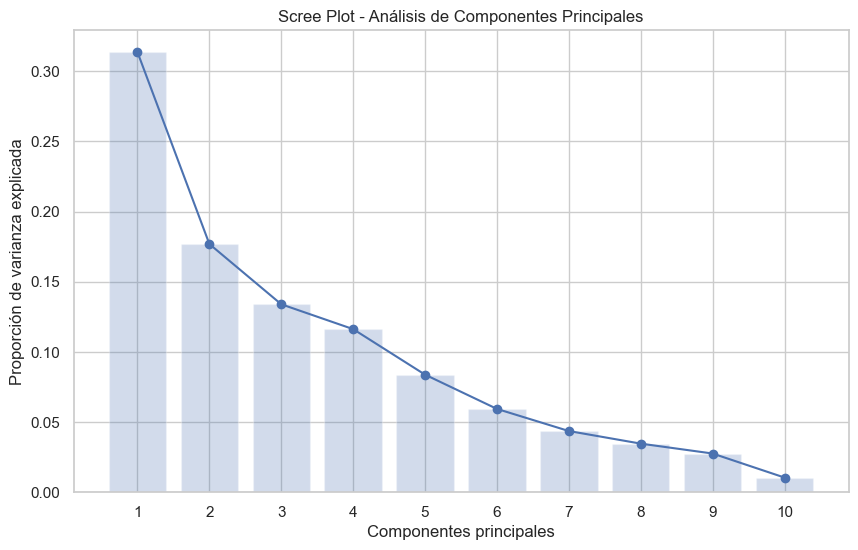

Varianza acumulada de los dos primeros componentes: 49.06 %


In [13]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(varianza_explicada) + 1),
    varianza_explicada,
    marker="o"
)

plt.bar(
    range(1, len(varianza_explicada) + 1),
    varianza_explicada,
    alpha=0.25
)

plt.xlabel("Componentes principales")
plt.ylabel("Proporción de varianza explicada")

plt.title("Scree Plot - Análisis de Componentes Principales")

plt.xticks(range(1, len(varianza_explicada) + 1))

plt.show()

print(
    "Varianza acumulada de los dos primeros componentes:",
    round(varianza_acumulada[1] * 100, 2),
    "%"
)

El gráfico permite identificar cuáles componentes principales concentran una mayor proporción de la variabilidad de los datos. También permite observar qué tan representativa es la reducción de las 10 variables a dos componentes.

## Reducción a dos componentes principales

Ahora reducimos las 10 variables a dos componentes principales.

In [14]:
pca_2 = PCA(n_components=2)

X_pca = pca_2.fit_transform(X_scaled)

X_pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

display(X_pca_df.head())

,PC1,PC2
0,-1.721700,-0.505994
1,-0.863993,1.310614
2,-0.808460,0.261339
3,2.274038,-0.112743
4,-1.692063,-0.303223


## Gráfico de dispersión

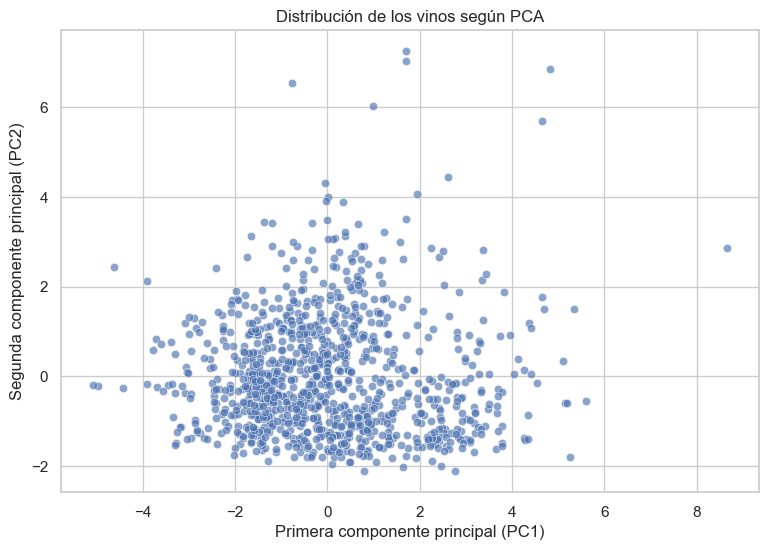

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=X_pca_df,
    x="PC1",
    y="PC2",
    alpha=0.65
)

plt.title("Distribución de los vinos según PCA")

plt.xlabel("Primera componente principal (PC1)")
plt.ylabel("Segunda componente principal (PC2)")

plt.show()

La representación gráfica permite observar la distribución de los vinos en dos dimensiones. Los puntos cercanos representan observaciones con características similares en el espacio de las componentes principales, mientras que los puntos alejados presentan mayores diferencias.

# 8. Selección de variables mediante correlación

En esta etapa identificaremos las variables que presentan una relación lineal elevada entre sí.

Para ello utilizaremos la matriz de correlación de Pearson.

## Matriz de correlación

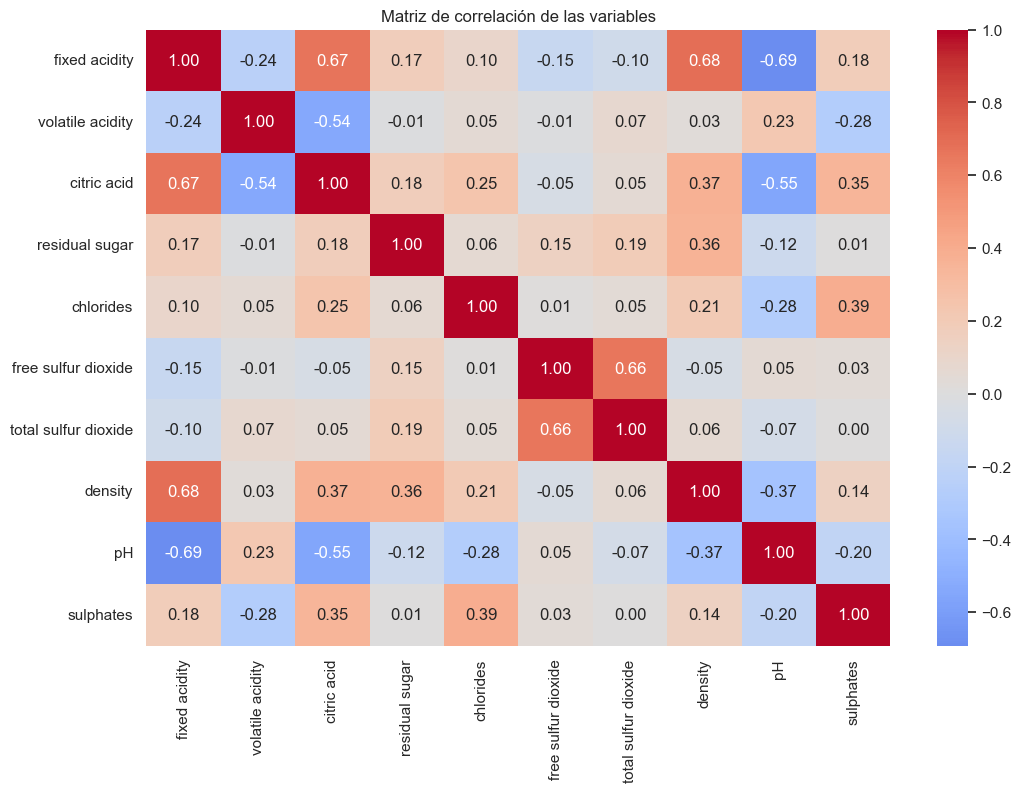

In [16]:
correlacion = X.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Matriz de correlación de las variables")

plt.show()

## Identificación de variables altamente correlacionadas

Establecemos un umbral de correlación absoluta de 0.85.

Cuando dos variables tengan una correlación superior a este valor, eliminaremos una de ellas para evitar redundancia.

In [18]:
umbral = 0.85

columnas = list(correlacion.columns)

eliminar = set()

print("Variables con correlación superior al umbral:")

for i in range(len(columnas)):

    for j in range(i + 1, len(columnas)):

        variable_1 = columnas[i]
        variable_2 = columnas[j]

        valor = correlacion.loc[variable_1, variable_2]

        if abs(valor) > umbral:

            print(
                variable_1,
                "y",
                variable_2,
                ":", round(valor, 3)
            )

            eliminar.add(variable_2)

# Conservar las variables no eliminadas
variables_seleccionadas = [
    col for col in columnas if col not in eliminar
]

print("\nVariables eliminadas:", sorted(eliminar))

print("\nVariables seleccionadas:", variables_seleccionadas)

print(
    "\nCantidad de variables seleccionadas:",
    len(variables_seleccionadas)
)

Variables con correlación superior al umbral:

Variables eliminadas: []

Variables seleccionadas: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates']

Cantidad de variables seleccionadas: 10


## Crear el conjunto de variables seleccionadas

In [19]:
X_seleccionado = X[variables_seleccionadas].copy()

# Estandarizar nuevamente
scaler_seleccionado = StandardScaler()

X_seleccionado_scaled = scaler_seleccionado.fit_transform(
    X_seleccionado
)

print("Dimensiones del nuevo conjunto:")

print(X_seleccionado_scaled.shape)

Dimensiones del nuevo conjunto:
(1016, 10)


La selección de variables permite reducir la dimensionalidad de los datos y evitar que características con información muy similar tengan una influencia redundante en el análisis. El conjunto resultante se utilizará para comparar el desempeño del algoritmo K-means.

# 9. Aplicación del algoritmo K-means

Ahora aplicaremos K-means utilizando tres enfoques:
* Modelo 1: las 10 variables originales estandarizadas.
* Modelo 2: las dos componentes principales obtenidas mediante PCA.
* Modelo 3: las variables seleccionadas mediante correlación.
Se evaluarán valores de K entre 2 y 6.

In [20]:
# Crear los tres conjuntos de datos
conjuntos = {
    "Datos originales": X_scaled,
    "PCA": X_pca,
    "Variables seleccionadas": X_seleccionado_scaled
}

resultados = []

# Evaluar K entre 2 y 6
for nombre, datos in conjuntos.items():

    for k in range(2, 7):

        modelo = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        etiquetas = modelo.fit_predict(datos)

        # Calcular métricas
        inercia = modelo.inertia_

        silhouette = silhouette_score(
            datos,
            etiquetas
        )

        resultados.append({
            "Enfoque": nombre,
            "K": k,
            "Inercia": inercia,
            "Silhouette": silhouette
        })

# Crear tabla de resultados
resultados_df = pd.DataFrame(resultados)

display(resultados_df.round(4))

,Enfoque,K,Inercia,Silhouette
0,Datos originales,2,8123.3925,0.2252
1,Datos originales,3,7097.7423,0.1983
2,Datos originales,4,6256.1077,0.2143
3,Datos originales,5,5690.6016,0.1772
4,Datos originales,6,5232.7179,0.1853
5,PCA,2,2969.3650,0.3997
6,PCA,3,2009.4527,0.3966
7,PCA,4,1508.1330,0.3728
8,PCA,5,1267.5761,0.3676
9,PCA,6,1089.6450,0.3600


Este procedimiento permite comparar el comportamiento del algoritmo K-means en los tres conjuntos de datos y observar cómo cambia la agrupación dependiendo de la representación de las variables.

# 10. Evaluación mediante el método del codo

El método del codo utiliza la inercia para analizar la cantidad adecuada de clusters.

La inercia mide qué tan cerca se encuentran las observaciones de los centros de sus respectivos grupos.

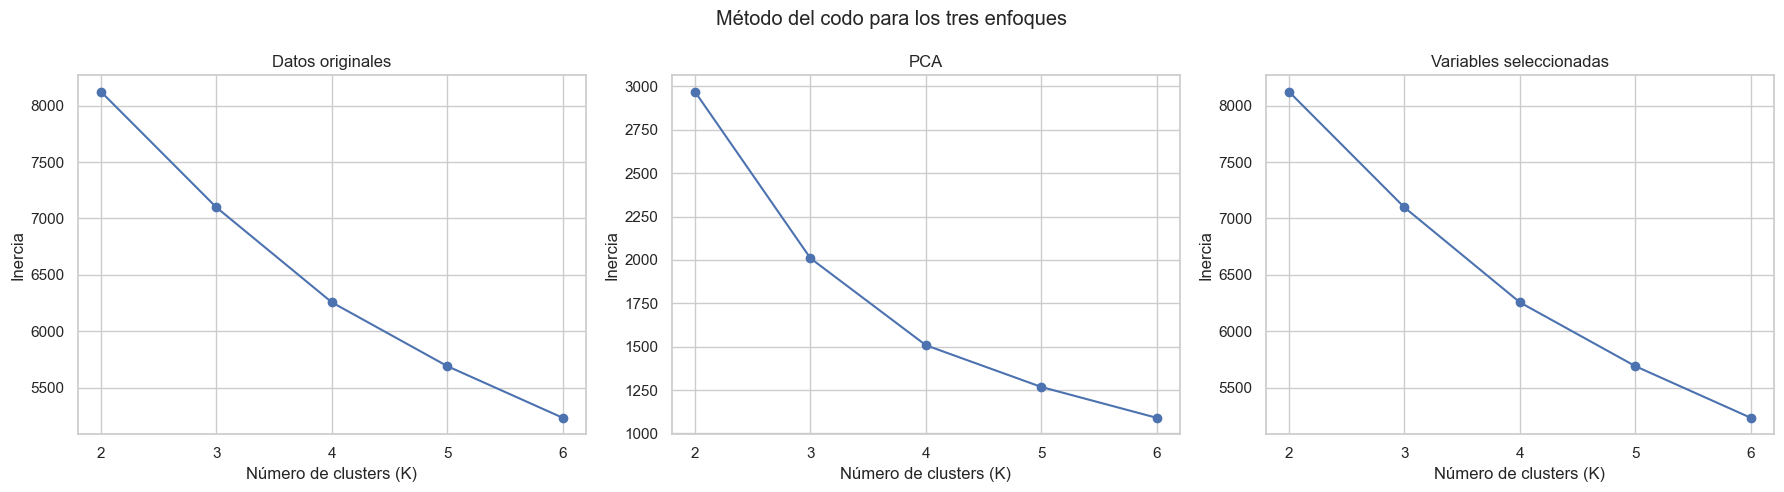

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nombre, grupo) in zip(
    axes,
    resultados_df.groupby("Enfoque", sort=False)
):

    ax.plot(
        grupo["K"],
        grupo["Inercia"],
        marker="o"
    )

    ax.set_title(nombre)

    ax.set_xlabel("Número de clusters (K)")

    ax.set_ylabel("Inercia")

    ax.set_xticks(range(2, 7))

plt.suptitle("Método del codo para los tres enfoques")

plt.tight_layout()

plt.show()

Se busca identificar el punto en el que la reducción de la inercia comienza a disminuir de manera menos pronunciada. Ese punto puede sugerir un número adecuado de clusters.

# 11. Evaluación mediante Silhouette Score

El Silhouette Score permite evaluar la calidad de la agrupación considerando la cohesión interna de los clusters y su separación respecto a los demás grupos.

Sus valores se interpretan de la siguiente manera:
* Cercano a 1: buena separación entre los grupos.
* Cercano a 0: los grupos presentan solapamiento.
* Negativo: algunas observaciones pueden estar asignadas a grupos inadecuados.

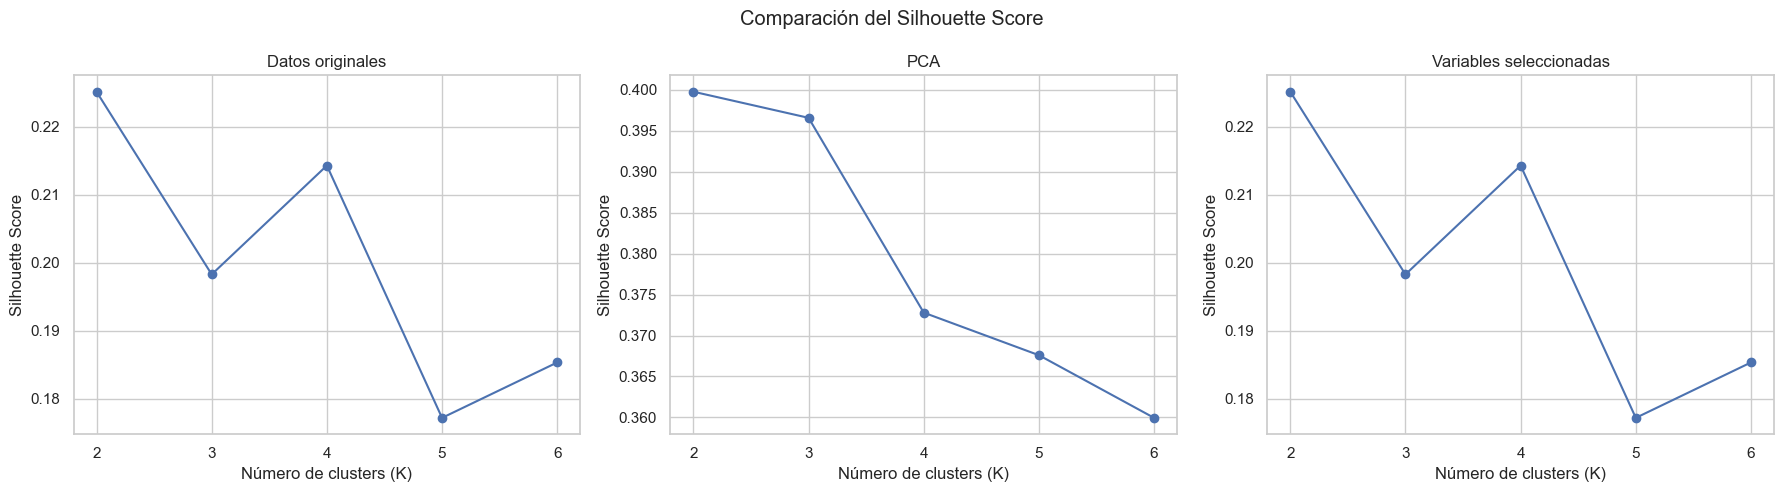

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nombre, grupo) in zip(
    axes,
    resultados_df.groupby("Enfoque", sort=False)
):

    ax.plot(
        grupo["K"],
        grupo["Silhouette"],
        marker="o"
    )

    ax.set_title(nombre)

    ax.set_xlabel("Número de clusters (K)")

    ax.set_ylabel("Silhouette Score")

    ax.set_xticks(range(2, 7))

plt.suptitle("Comparación del Silhouette Score")

plt.tight_layout()

plt.show()

El enfoque que presente un mayor Silhouette Score tendrá una mejor separación relativa de los grupos para el valor de K evaluado.

# 12. Comparación de los tres enfoques

Ahora organizamos los resultados en una tabla comparativa.

In [23]:
comparacion = resultados_df.sort_values(
    by="Silhouette",
    ascending=False
).reset_index(drop=True)

display(comparacion.round(4))

,Enfoque,K,Inercia,Silhouette
0,PCA,2,2969.3650,0.3997
1,PCA,3,2009.4527,0.3966
2,PCA,4,1508.1330,0.3728
3,PCA,5,1267.5761,0.3676
4,PCA,6,1089.6450,0.3600
5,Variables seleccionadas,2,8123.3925,0.2252
6,Datos originales,2,8123.3925,0.2252
7,Variables seleccionadas,4,6256.1077,0.2143
8,Datos originales,4,6256.1077,0.2143
9,Datos originales,3,7097.7423,0.1983


Identificamos la combinación con mayor Silhouette Score:

In [24]:
mejor = comparacion.iloc[0]

print("Mejor enfoque:", mejor["Enfoque"])

print("Número de clusters:", int(mejor["K"]))

print("Silhouette Score:", round(mejor["Silhouette"], 4))

print("Inercia:", round(mejor["Inercia"], 4))

Mejor enfoque: PCA
Número de clusters: 2
Silhouette Score: 0.3997
Inercia: 2969.365


La tabla permite identificar qué representación de los datos genera una mejor separación relativa entre los grupos. Sin embargo, la decisión final también debe considerar el método del codo y la facilidad de interpretar las características de cada cluster.

# 13. Selección del modelo final

Seleccionamos el modelo que obtuvo el mayor Silhouette Score y lo utilizamos para identificar las agrupaciones definitivas.

In [25]:
# Identificar el mejor enfoque y K
enfoque_final = mejor["Enfoque"]

k_final = int(mejor["K"])

# Seleccionar los datos correspondientes
datos_finales = conjuntos[enfoque_final]

# Crear el modelo final
modelo_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

# Obtener los clusters
clusters = modelo_final.fit_predict(datos_finales)

# Incorporar los resultados a las variables originales
resultado_final = X.copy()

resultado_final["Cluster"] = clusters

display(resultado_final.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,Cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,0


## Distribución de los clusters

In [26]:
print("Cantidad de observaciones por cluster:")

display(
    resultado_final["Cluster"].value_counts().sort_index()
)

Cantidad de observaciones por cluster:


Cluster
0    689
1    327
Name: count, dtype: int64

## Caracterización de los clusters

Calculamos los promedios de las 10 variables originales para observar las diferencias entre los grupos.

In [27]:
perfil_clusters = resultado_final.groupby(
    "Cluster"
)[variables].mean()

display(perfil_clusters.round(3))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates
Cluster,,,,,,,,,,
0,7.424,0.581,0.174,2.357,0.079,17.015,50.155,0.996,3.370,0.612
1,10.124,0.434,0.470,2.874,0.105,12.768,38.070,0.998,3.186,0.751


Esta tabla permitirá analizar qué características fisicoquímicas predominan en cada grupo.

Por ejemplo, podremos observar si determinados clusters presentan mayor acidez fija, mayor contenido de sulfatos o concentraciones diferentes de dióxido de azufre.

## Visualización de los clusters

Representamos los grupos en las dos primeras componentes principales.

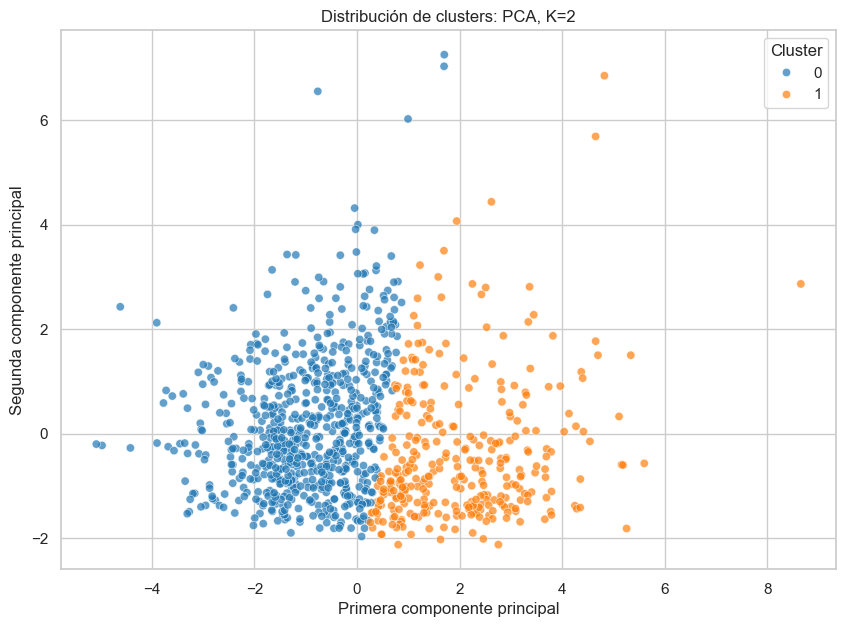

In [28]:
visualizacion = X_pca_df.copy()

visualizacion["Cluster"] = clusters

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=visualizacion,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title(
    f"Distribución de clusters: {enfoque_final}, K={k_final}"
)

plt.xlabel("Primera componente principal")

plt.ylabel("Segunda componente principal")

plt.legend(title="Cluster")

plt.show()

# 14. Interpretación general de resultados

Los resultados obtenidos permiten identificar dos grupos de vinos con características fisicoquímicas diferentes, a partir de la aplicación del algoritmo K-means y el análisis de componentes principales (PCA).

En primer lugar, la base de datos contaba con 1.143 observaciones y 10 variables numéricas. Durante la limpieza se eliminaron los registros duplicados, obteniendo finalmente 1.016 observaciones, sin valores faltantes ni registros repetidos. Posteriormente, se estandarizaron las variables para evitar que las diferencias en sus escalas afectaran los resultados del modelo.

En el análisis de componentes principales se encontró que las dos primeras componentes explican conjuntamente el 49,06 % de la variabilidad de los datos. Esto permitió representar las observaciones en dos dimensiones y facilitar su análisis, aunque implica que una parte importante de la información original no queda recogida en esta representación.

Por otra parte, la matriz de correlación no identificó variables con una correlación superior al umbral establecido de 0,85. Por esta razón, se conservaron las 10 variables originales para el enfoque de selección de variables.

Al comparar los tres enfoques utilizados para K-means, se encontró que el modelo basado en PCA presentó el mejor resultado, con dos clusters y un Silhouette Score de 0,3997. Este valor indica una separación moderada entre los grupos, lo que evidencia que existen diferencias en las características fisicoquímicas de los vinos, aunque los clusters no están completamente separados.

En cuanto a la caracterización de los grupos, se identificaron las siguientes diferencias:

* Cluster 0: reúne 689 observaciones (67,8 % aproximadamente). Se caracteriza por presentar menores niveles de acidez fija, ácido cítrico, cloruros, densidad y sulfatos. Asimismo, presenta mayores promedios de acidez volátil y dióxido de azufre libre y total.

* Cluster 1: agrupa 327 observaciones (32,2 % aproximadamente). Presenta mayores niveles de acidez fija, ácido cítrico, azúcar residual, cloruros, densidad y sulfatos. También registra menores valores promedio de acidez volátil y dióxido de azufre libre y total.

Estas diferencias muestran que el algoritmo logró identificar dos agrupaciones con perfiles fisicoquímicos distintos. Es importante aclarar que los clusters representan similitudes entre las características analizadas y no necesariamente categorías de calidad del vino, ya que el modelo no utilizó una variable de calidad para realizar la agrupación.

En general, los resultados muestran que la reducción de dimensionalidad mediante PCA permitió obtener una agrupación más definida que la obtenida con las 10 variables originales, de acuerdo con el indicador Silhouette Score.

# 15. Conclusiones

1. La aplicación de técnicas de aprendizaje no supervisado permitió identificar dos grupos de vinos con características fisicoquímicas diferentes, demostrando la utilidad de estos métodos para encontrar patrones y estructuras dentro de un conjunto de datos sin utilizar etiquetas previamente definidas.

2. El análisis de componentes principales (PCA) fue el enfoque que presentó el mejor desempeño en la agrupación, con un Silhouette Score de 0,3997 y dos clusters. Esto indica que la transformación de las variables permitió obtener una mejor separación relativa de las observaciones frente a los otros enfoques evaluados.

3. La caracterización de los clusters evidenció diferencias importantes en variables como acidez fija, acidez volátil, ácido cítrico, cloruros y sulfatos. Estas diferencias permitieron reconocer dos perfiles fisicoquímicos distintos dentro de la muestra analizada.

4. La comparación de los modelos permitió comprobar que una mayor cantidad de variables no garantiza necesariamente una mejor agrupación. La representación de los datos mediante componentes principales puede facilitar la identificación de patrones y mejorar el desempeño del algoritmo K-means.

5. Finalmente, aunque se identificaron agrupaciones con características diferenciadas, el valor del Silhouette Score muestra que la separación entre los grupos es moderada. Por lo tanto, los resultados deben interpretarse como una aproximación a la segmentación de los vinos y no como una clasificación definitiva de su calidad.